In [7]:
import requests, pandas as pd

url = "https://wcc.sc.egov.usda.gov/awdbRestApi/services/v1/data"
params = {
    "stationTriplets": "679:WA:SNTL",
    "elements": "WTEQ,SNWD,PREC,TAVG",
    "duration": "DAILY",
    "beginDate": "1979-10-01",
    "endDate": "2026-10-05",
}
r = requests.get(url, params=params, timeout=60)
r.raise_for_status()
raw = r.json()

frames = []
for block in raw[0]["data"]:
    code = block["stationElement"]["elementCode"]
    s = pd.DataFrame(block["values"]).set_index("date")["value"].rename(code)
    frames.append(s)

df = pd.concat(frames, axis=1)
df.index = pd.to_datetime(df.index)
df.to_csv("paradise_snotel_daily.csv")
df.describe()

,PREC,SNWD,TAVG,WTEQ
count,16396.000000,7180.000000,13643.000000,16076.000000
mean,76.774872,62.832312,38.503474,30.453913
std,40.510325,61.748318,12.520212,30.242094
min,0.000000,0.000000,-9.000000,0.000000
25%,44.300000,0.000000,29.500000,0.000000
50%,85.100000,49.500000,36.300000,22.500000
75%,108.200000,116.000000,47.100000,55.700000
max,179.600000,228.000000,80.600000,123.100000


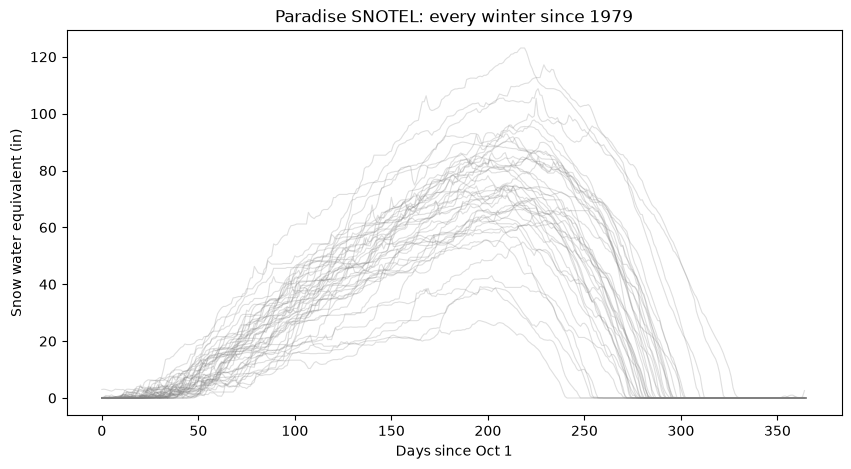

In [8]:
import matplotlib.pyplot as plt

df["water_year"] = df.index.year + (df.index.month >= 10)
wy_start = pd.to_datetime((df["water_year"] - 1).astype(str) + "-10-01")
df["day_of_wy"] = (df.index.to_series() - wy_start).dt.days

fig, ax = plt.subplots(figsize=(10, 5))
for wy, g in df.groupby("water_year"):
    ax.plot(g["day_of_wy"], g["WTEQ"], color="gray", alpha=0.25, lw=0.8)
ax.set_xlabel("Days since Oct 1")
ax.set_ylabel("Snow water equivalent (in)")
ax.set_title("Paradise SNOTEL: every winter since 1979")
plt.show()

In [10]:
print(df.head(400))

            PREC  SNWD  TAVG  WTEQ  water_year  day_of_wy
date                                                     
1980-10-01   0.0   NaN   NaN   0.0        1981          0
1980-10-02   0.0   NaN   NaN   0.0        1981          1
1980-10-03   0.0   NaN   NaN   0.0        1981          2
1980-10-04   0.0   NaN   NaN   0.0        1981          3
1980-10-05   0.0   NaN   NaN   0.0        1981          4
...          ...   ...   ...   ...         ...        ...
1982-10-31  13.7   NaN   NaN   NaN        1983         30
1982-11-01  13.7   NaN   NaN   NaN        1983         31
1982-11-02  13.7   NaN   NaN   NaN        1983         32
1982-11-03  13.7   NaN   NaN   NaN        1983         33
1982-11-04  14.5   NaN   NaN   NaN        1983         34

[400 rows x 6 columns]


In [11]:
df.shape

(16441, 6)

In [12]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 16441 entries, 1980-10-01 to 1980-09-30
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   PREC        16396 non-null  float64
 1   SNWD        7180 non-null   float64
 2   TAVG        13643 non-null  float64
 3   WTEQ        16076 non-null  float64
 4   water_year  16441 non-null  int32  
 5   day_of_wy   16441 non-null  int64  
dtypes: float64(4), int32(1), int64(1)
memory usage: 834.9 KB


In [13]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PREC,16396.0,76.774872,40.510325,0.0,44.3,85.1,108.2,179.6
SNWD,7180.0,62.832312,61.748318,0.0,0.0,49.5,116.0,228.0
TAVG,13643.0,38.503474,12.520212,-9.0,29.5,36.3,47.1,80.6
WTEQ,16076.0,30.453913,30.242094,0.0,0.0,22.5,55.7,123.1
water_year,16441.0,2003.982300,13.030616,1980.0,1993.0,2004.0,2015.0,2027.0
day_of_wy,16441.0,182.070312,105.474985,0.0,91.0,182.0,273.0,365.0


In [26]:
#Load the data and count missing values per column
import pandas as pd
df = pd.read_csv("paradise_snotel_daily.csv", index_col=0, parse_dates=True)
cols = ["WTEQ", "SNWD", "PREC", "TAVG"]

print(df[cols].isna().sum())
print(df[cols].isna().mean().round(3))   # share missing

WTEQ     365
SNWD    9261
PREC      45
TAVG    2798
dtype: int64
WTEQ    0.022
SNWD    0.563
PREC    0.003
TAVG    0.170
dtype: float64


In [27]:
#Check for days missing from the table entirely
full = pd.date_range(df.index.min(), df.index.max(), freq="D")
print(len(full) - len(df), "days have no row")

366 days have no row


In [28]:
#Sorting the table :

#sort the table and fill in missing days as explicit rows

df = pd.read_csv("paradise_snotel_daily.csv", index_col=0, parse_dates=True).sort_index()
df = df.reindex(pd.date_range(df.index.min(), df.index.max(), freq="D"))
df["water_year"] = df.index.year + (df.index.month >= 10)

In [29]:
# Recheck if the missing rows are now explicit in the table:
full = pd.date_range(df.index.min(), df.index.max(), freq="D")
print(len(full) - len(df), "days have no row")

0 days have no row


In [30]:
#See which years have gaps
df["water_year"] = df.index.year + (df.index.month >= 10)
by_year = df[cols].isna().groupby(df["water_year"]).sum()
print(by_year[(by_year > 0).any(axis=1)])

            WTEQ  SNWD  PREC  TAVG
water_year                        
1980           0     1     1     1
1981           1   365     0   365
1982         365   365   365   365
1983         364   365     0   365
1984           0   366     0   366
1985           0   365     0   365
1986           0   365     0   365
1987           0   365     0   365
1988           0   366     0   365
1989           0   365     0    48
1990           0   365     0    27
1991           0   365     0     0
1992           0   366     0     0
1993           0   365     0     1
1994           0   365     0    37
1995           0   365     0     1
1996           0   366     0     1
1997           0   365     0     3
1998           0   365     0     0
1999           0   365     0    15
2000           0   366     0     1
2001           0   365     0     1
2002           0   365     0     1
2003           0   365     0     1
2004           0   366     0    89
2005           0   365     0     0
2006           0   3

In [32]:
#Find the longest gap per column
for c in cols:
    is_na = df[c].isna()
    run = is_na.groupby((~is_na).cumsum()).sum()
    print(c, "longest gap:", run.max(), "days")

WTEQ longest gap: 730 days
SNWD longest gap: 9452 days
PREC longest gap: 365 days
TAVG longest gap: 2922 days


In [33]:
# How to Handle missing data :
# How to decide what to do

# Short gaps (1-3 days): interpolate. Snow and temperature change smoothly enough that this is safe: df[c] = df[c].interpolate(limit=3)
# Long gaps (weeks or more): leave them as NaN. Don't invent data.
# A whole winter missing key data: drop that water year from the analysis, and note it in your write-up.
# Summer snow readings that are NaN or 0: normal, since there's no snow. Not a real gap.

In [34]:
# Find exactly where each gap sits:
for c in ["WTEQ", "PREC", "TAVG"]:
    is_na = df[c].isna()
    grp = (~is_na).cumsum()
    runs = is_na.groupby(grp).agg(["sum"])
    longest = runs["sum"].idxmax()
    dates = df.index[(grp == longest) & is_na]
    print(c, dates.min().date(), "to", dates.max().date(), len(dates), "days")



WTEQ 1981-09-30 to 1983-09-29 730 days
PREC 1981-10-01 to 1982-09-30 365 days
TAVG 1980-09-30 to 1988-09-29 2922 days


In [ ]:
# Decisions

# Snowpack story (Post 1, first half): use WY1980, 1981, and 1984 onward. That's about 40 winters, which is plenty.
# Rain vs. snow angle (needs temperature): use WY1980 and WY1989 onward, about 38 winters. Say "since 1989" in the post, since that's where the temperature record is continuous.
# WY2027: it only started on Oct 1, so keep it out of the history. We'll use it for the forecast in Post 2.
# Nothing gets interpolated. These are all multi-year blocks, so filling them in would be inventing data.

In [35]:
df = df[df["water_year"].between(1989, 2026)].copy()
print(df["water_year"].nunique(), "winters")
print(df[["WTEQ", "PREC", "TAVG"]].isna().sum())

38 winters
WTEQ      1
PREC     43
TAVG    242
dtype: int64


In [36]:
for c in ["WTEQ", "PREC", "TAVG"]:
    is_na = df[c].isna()
    grp = (~is_na).cumsum()
    runs = is_na[is_na].groupby(grp[is_na]).agg(lambda s: (s.index.min().date(), s.index.max().date(), len(s)))
    print(c)
    print(runs.tolist())

WTEQ
[(datetime.date(2021, 8, 19), datetime.date(2021, 8, 19), 1)]
PREC
[(datetime.date(2021, 8, 19), datetime.date(2021, 9, 30), 43)]
TAVG
[(datetime.date(1989, 1, 8), datetime.date(1989, 1, 8), 1), (datetime.date(1989, 1, 13), datetime.date(1989, 1, 16), 4), (datetime.date(1989, 1, 18), datetime.date(1989, 1, 23), 6), (datetime.date(1989, 1, 25), datetime.date(1989, 1, 26), 2), (datetime.date(1989, 1, 28), datetime.date(1989, 2, 10), 14), (datetime.date(1989, 2, 12), datetime.date(1989, 2, 17), 6), (datetime.date(1989, 2, 19), datetime.date(1989, 2, 22), 4), (datetime.date(1989, 3, 2), datetime.date(1989, 3, 2), 1), (datetime.date(1989, 3, 8), datetime.date(1989, 3, 8), 1), (datetime.date(1989, 3, 25), datetime.date(1989, 3, 25), 1), (datetime.date(1989, 3, 28), datetime.date(1989, 3, 28), 1), (datetime.date(1989, 3, 30), datetime.date(1989, 3, 31), 2), (datetime.date(1989, 4, 2), datetime.date(1989, 4, 2), 1), (datetime.date(1989, 4, 4), datetime.date(1989, 4, 5), 2), (datetime.date

In [39]:
# Filling the 3-day gaps with interpolation, and leaving the longer gaps as NaN.

#One correction to my earlier advice: interpolate(limit=3) fills the first 3 days of a longer gap and leaves the rest, which would partially fill the 14- and 89-day blocks. Use this version, which only fills gaps of 3 days or fewer:

def fill_short(s, n=3):
    gap = s.isna().groupby(s.notna().cumsum()).transform("sum")
    return s.interpolate().where(~(s.isna() & (gap > n)))

df["WTEQ"] = fill_short(df["WTEQ"])
df["TAVG"] = fill_short(df["TAVG"])

In [40]:


winter = df[df.index.month.isin([11, 12, 1, 2, 3, 4])]
cov = winter[["WTEQ", "PREC", "TAVG"]].notna().groupby(winter["water_year"]).mean().round(3)
print(cov[(cov < 1).any(axis=1)])

            WTEQ  PREC   TAVG
water_year                   
1989         1.0   1.0  0.812
1999         1.0   1.0  0.928


"Window: WY1990-WY2026. WY1989 excluded (winter temperature coverage 81%). Gaps of 3 days or fewer were interpolated. Longer gaps were left as missing."

One reminder: WY2026 ended Sep 30, 2026, so it's a full year. WY2027 started Oct 1 and stays out of the history.

That finishes Step 3. Step 5 is next: measure each winter. Try writing it yourself:

Group by water_year.
Peak snowpack: the max of WTEQ.
Peak date: idxmax() on WTEQ.
Melt-out date: the first date after the peak where WTEQ drops to 0.
Winter precipitation: the sum of daily PREC change from Nov to Apr, or the difference between PREC on Apr 30 and Oct 1 (note: PREC is cumulative, so don't sum it directly).
Winter temperature: the mean TAVG for Nov-Apr.

In [41]:

df = df[df["water_year"].between(1990, 2026)].copy()
print(df["water_year"].nunique(), "winters")

37 winters


#Step 5 (summary table):

In [42]:

rows = []
for wy, g in df.groupby("water_year"):
    peak_date = g["WTEQ"].idxmax()
    after = g.loc[peak_date:, "WTEQ"]
    zero = after[after <= 0]
    winter = g[g.index.month.isin([11, 12, 1, 2, 3, 4])]
    rows.append({
        "water_year": wy,
        "peak_swe_in": g["WTEQ"].max(),
        "peak_date": peak_date,
        "melt_out_date": zero.index[0] if len(zero) else pd.NaT,
        "winter_precip_in": g.loc[f"{wy}-04-30", "PREC"] - g.loc[f"{wy-1}-10-31", "PREC"],
        "winter_temp_f": winter["TAVG"].mean(),
    })

summary = pd.DataFrame(rows).set_index("water_year")
summary

,peak_swe_in,peak_date,melt_out_date,winter_precip_in,winter_temp_f
water_year,,,,,
1990,78.6,1990-04-01,1990-07-21,96.5,31.361326
1991,84.3,1991-05-09,1991-07-31,100.2,28.446961
1992,55.7,1992-04-17,1992-06-17,75.0,33.387912
1993,68.0,1993-05-05,1993-07-07,66.1,27.842541
1994,63.6,1994-04-13,1994-07-12,67.9,30.979834
1995,81.8,1995-05-01,1995-07-10,92.5,29.118232
1996,66.9,1996-05-13,1996-07-13,123.6,30.329670
1997,123.1,1997-05-06,1997-08-07,141.3,28.827624
1998,71.4,1998-04-24,1998-07-15,79.0,30.788398


In [ ]:
%pip install scipy

In [ ]:
#Step 6: is peak snowpack trending?

slope: -0.16 in/yr, p = 0.62


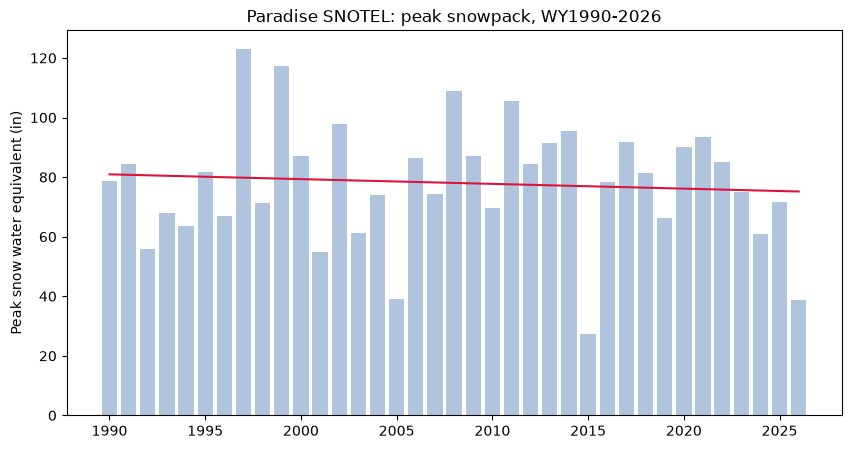

In [45]:
import matplotlib.pyplot as plt
from scipy import stats

res = stats.linregress(summary.index, summary["peak_swe_in"])
print(f"slope: {res.slope:.2f} in/yr, p = {res.pvalue:.2f}")

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(summary.index, summary["peak_swe_in"], color="lightsteelblue")
ax.plot(summary.index, res.intercept + res.slope * summary.index, color="crimson")
ax.set_ylabel("Peak snow water equivalent (in)")
ax.set_title("Paradise SNOTEL: peak snowpack, WY1990-2026")
plt.show()

Honest reading: no detectable trend in peak snowpack since 1990.

The slope works out to about -6 inches over the 37 years, but with a p-value of 0.62 that's well within noise. Peak snowpack here swings from 27 to 123 inches year to year, which drowns out any slow drift.
Don't write "Rainier snow is declining." The data doesn't support it. What it does support is "peak snowpack is wildly variable, and the swings aren't random."



                  peak_swe_in  winter_precip_in  winter_temp_f
peak_swe_in              1.00              0.66          -0.73
winter_precip_in         0.66              1.00          -0.36
winter_temp_f           -0.73             -0.36           1.00


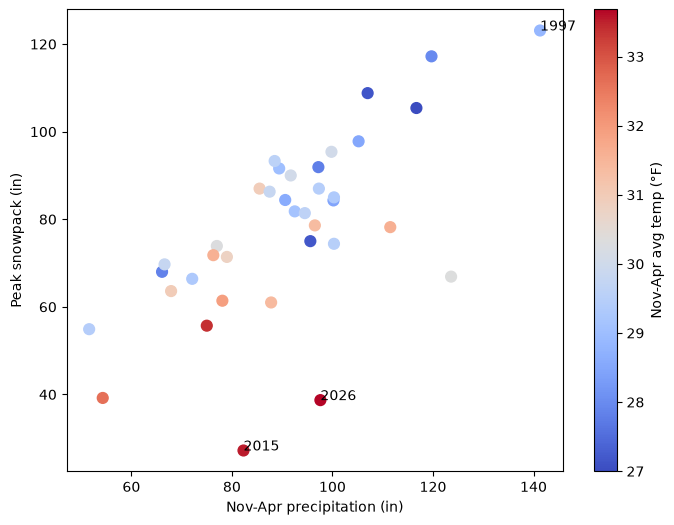

In [47]:
#Step 7: Precipitation Vs Temperature Vs Snowpack

print(summary[["peak_swe_in", "winter_precip_in", "winter_temp_f"]].corr().round(2))

fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(summary["winter_precip_in"], summary["peak_swe_in"],
                c=summary["winter_temp_f"], cmap="coolwarm", s=60)
plt.colorbar(sc, label="Nov-Apr avg temp (°F)")
for wy in [1997, 2015, 2026]:
    ax.annotate(str(wy), (summary.loc[wy, "winter_precip_in"], summary.loc[wy, "peak_swe_in"]))
ax.set_xlabel("Nov-Apr precipitation (in)")
ax.set_ylabel("Peak snowpack (in)")
plt.show()

This is the key result, and it's a good one.

Temperature (-0.73) tracks peak snowpack more strongly than precipitation does (+0.66). At Paradise, how warm the winter was says more about the snowpack than how wet it was. That supports "a wet winter isn't a snowy winter."
Precipitation and temperature are only weakly linked (-0.36). They carry mostly separate information, so together they should explain more than either alone.

In [48]:
%pip install statsmodels

86789.80s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 16.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [statsmodels] [statsmodels]

[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [49]:
import statsmodels.api as sm

X = sm.add_constant(summary[["winter_precip_in", "winter_temp_f"]])
model = sm.OLS(summary["peak_swe_in"], X).fit()
print(model.summary().tables[1])
print("R²:", round(model.rsquared, 2))

                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const              230.4146     38.590      5.971      0.000     151.991     308.838
winter_precip_in     0.5047      0.106      4.747      0.000       0.289       0.721
winter_temp_f       -6.6222      1.136     -5.828      0.000      -8.932      -4.313
R²: 0.72


In [50]:
res_t = stats.linregress(summary.index, summary["winter_temp_f"])
print(f"{res_t.slope*10:.2f} °F per decade, p = {res_t.pvalue:.2f}")

0.07 °F per decade, p = 0.80


#Meltdown timing test

In [51]:
res_m = stats.linregress(summary["winter_temp_f"], summary["melt_out_date"].dt.dayofyear)
print(f"{res_m.slope:.1f} days per +1°F, p = {res_m.pvalue:.3f}, r = {res_m.rvalue:.2f}")

-7.3 days per +1°F, p = 0.000, r = -0.70


Wrdings for post - Wording for the post: “Each 1°F of extra winter warmth went with melt-out about a week earlier.” Keep the caveats: it’s correlation, one station, and Nov-Apr temperature includes the spring melt season, so part of the link is the melt itself.

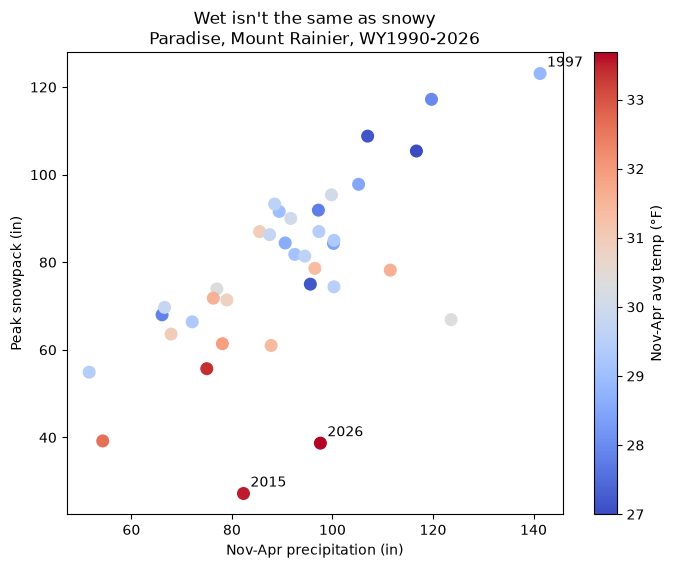

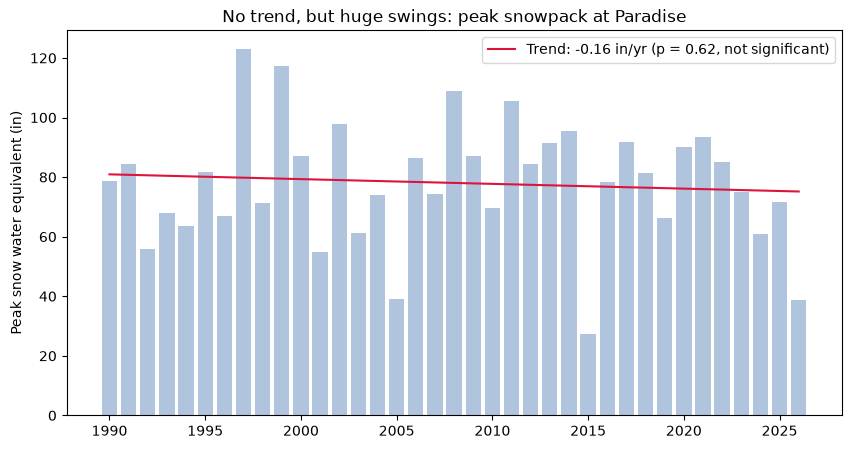

In [52]:
import os
os.makedirs("images", exist_ok=True)

# Chart 1: precipitation vs. peak snow, colored by temperature
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(summary["winter_precip_in"], summary["peak_swe_in"],
                c=summary["winter_temp_f"], cmap="coolwarm", s=70)
plt.colorbar(sc, label="Nov-Apr avg temp (°F)")
for wy in [1997, 2015, 2026]:
    ax.annotate(str(wy), (summary.loc[wy, "winter_precip_in"], summary.loc[wy, "peak_swe_in"]),
                xytext=(5, 5), textcoords="offset points")
ax.set_xlabel("Nov-Apr precipitation (in)")
ax.set_ylabel("Peak snowpack (in)")
ax.set_title("Wet isn't the same as snowy\nParadise, Mount Rainier, WY1990-2026")
plt.savefig("images/scatter.png", dpi=200, bbox_inches="tight")
plt.show()

# Chart 2: peak snowpack by year
res = stats.linregress(summary.index, summary["peak_swe_in"])
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(summary.index, summary["peak_swe_in"], color="lightsteelblue")
ax.plot(summary.index, res.intercept + res.slope * summary.index, color="crimson",
        label=f"Trend: {res.slope:.2f} in/yr (p = {res.pvalue:.2f}, not significant)")
ax.set_ylabel("Peak snow water equivalent (in)")
ax.set_title("No trend, but huge swings: peak snowpack at Paradise")
ax.legend()
plt.savefig("images/peak_trend.png", dpi=200, bbox_inches="tight")
plt.show()

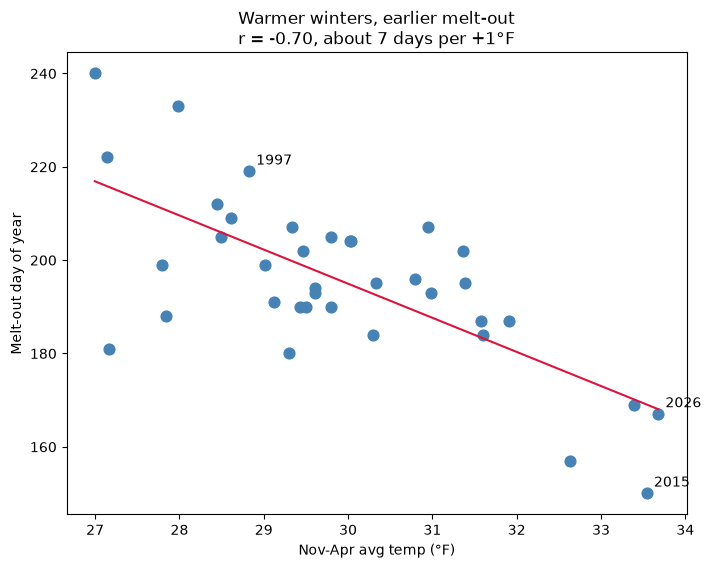

In [58]:
import numpy as np
import matplotlib.pyplot as plt

doy = summary["melt_out_date"].dt.dayofyear
fit = np.polyfit(summary["winter_temp_f"], doy, 1)
xs = np.linspace(summary["winter_temp_f"].min(), summary["winter_temp_f"].max(), 50)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(summary["winter_temp_f"], doy, color="steelblue", s=60)
ax.plot(xs, np.polyval(fit, xs), color="crimson")
for wy in [1997, 2015, 2026]:
    ax.annotate(str(wy), (summary.loc[wy, "winter_temp_f"], doy[wy]),
                xytext=(5, 5), textcoords="offset points")
ax.set_xlabel("Nov-Apr avg temp (°F)")
ax.set_ylabel("Melt-out day of year")
ax.set_title("Warmer winters, earlier melt-out\nr = -0.70, about 7 days per +1°F")
plt.savefig("images/meltout.png", dpi=200, bbox_inches="tight")
plt.show()

In [54]:
#summary

In [55]:
# Melt-out as day of year (bigger = snow lasted longer)
summary["melt_doy"] = summary["melt_out_date"].dt.dayofyear

# Rank each winter (1 = best) on peak snowpack and on how long snow lasted
summary["rank_peak"] = summary["peak_swe_in"].rank(ascending=False)
summary["rank_melt"] = summary["melt_doy"].rank(ascending=False)

# Average the two ranks, then rank the winters overall
summary["score"] = (summary["rank_peak"] + summary["rank_melt"]) / 2
summary["overall_rank"] = summary["score"].rank(method="min").astype(int)

# Letter grades by percentile (top 20% = A, next 20% = B, ...)
pct = summary["overall_rank"] / len(summary)
summary["grade"] = pd.cut(pct, [0, .2, .4, .6, .8, 1.0], labels=list("ABCDF"))

cols = ["peak_swe_in", "melt_out_date", "winter_temp_f", "overall_rank", "grade"]
ranked = summary.sort_values("overall_rank")[cols]

print("RAINIER AT ITS BEST")
print(ranked.head(5))
print("\nRAINIER AT ITS WORST")
print(ranked.tail(5))
print("\n2026:")
print(ranked.loc[[2026]])

RAINIER AT ITS BEST
            peak_swe_in melt_out_date  winter_temp_f  overall_rank grade
water_year                                                              
1999              117.2    1999-08-21      27.977083             1     A
1997              123.1    1997-08-07      28.827624             2     A
2011              105.4    2011-08-28      26.996133             2     A
2008              108.8    2008-08-09      27.136264             4     A
2002               97.8    2002-07-24      28.488950             5     A

RAINIER AT ITS WORST
            peak_swe_in melt_out_date  winter_temp_f  overall_rank grade
water_year                                                              
2019               66.4    2019-06-29      29.297238            33     F
1992               55.7    1992-06-17      33.387912            34     F
2005               39.2    2005-06-06      32.627072            35     F
2026               38.7    2026-06-16      33.681215            35     F
2015     

In [56]:
import os
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib import cm, colors

os.makedirs("images", exist_ok=True)

years = summary.index.tolist()
peaks = summary["peak_swe_in"].values
temps = summary["winter_temp_f"].values
n = len(years)

norm = colors.Normalize(vmin=27, vmax=34)   # fixed range so colors stay consistent
cmap = plt.get_cmap("coolwarm")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.set_xlim(years[0] - 1, years[-1] + 1)
ax.set_ylim(0, 135)
ax.set_ylabel("Peak snowpack (in)")
ax.set_title("Peak snowpack at Paradise, Mount Rainier, WY1990-2026")
fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label="Nov-Apr avg temp (°F)")
label = ax.text(0.02, 0.92, "", transform=ax.transAxes, fontsize=12)

hold = 15  # extra frames at the end so people can read the final chart

def update(frame):
    if frame < n:
        ax.bar(years[frame], peaks[frame], color=cmap(norm(temps[frame])), width=0.8)
        label.set_text(f"WY{years[frame]}: {peaks[frame]:.0f} in peak, {temps[frame]:.1f}°F")
    elif frame == n:
        i = years.index(2026)
        ax.annotate("2026: warmest winter,\nonly 39 in", (2026, peaks[i]),
                    xytext=(2008, 118), arrowprops=dict(arrowstyle="->"), fontsize=10)
        label.set_text("Warm winters, short bars")

ani = animation.FuncAnimation(fig, update, frames=n + hold, repeat=True)
ani.save("images/rainier_snowpack.gif", writer=animation.PillowWriter(fps=5), dpi=100)
plt.close(fig)

In [57]:
import numpy as np

vis = summary[["peak_swe_in", "winter_temp_f"]].copy()
vis["snow_reveal_pct"] = (vis["peak_swe_in"] / vis["peak_swe_in"].max() * 100).round().astype(int)

t = ((vis["winter_temp_f"] - 27) / 7).clip(0, 1)
cold, warm = np.array([0x5B, 0x8F, 0xCB]), np.array([0xD9, 0x90, 0x6E])
vis["sky_hex"] = ["#%02X%02X%02X" % tuple((cold + (warm - cold) * x).round().astype(int)) for x in t]

vis["temp_f"] = vis.pop("winter_temp_f").round(1)
vis = vis.rename(columns={"peak_swe_in": "peak_in"})
vis.to_csv("images/snowline_keyframes.csv")
vis

,peak_in,snow_reveal_pct,sky_hex,temp_f
water_year,,,,
1990,78.6,64,#AA9091,31.4
1991,84.3,68,#758FB8,28.4
1992,55.7,45,#CE9076,33.4
1993,68.0,55,#6A8FC0,27.8
1994,63.6,52,#A39096,31.0
1995,81.8,66,#818FAF,29.1
1996,66.9,54,#978F9F,30.3
1997,123.1,100,#7C8FB3,28.8
1998,71.4,58,#9F9099,30.8
